# LSTM-Based Time-Series Forecasting of Apple Stock Prices

**Author**: Ashley Kennedy

In this project, I will use historical Apple (`AAPL`) stock data to build a Long Short-Term Memory (LSTM) model in PyTorch for time-series forecasting.  The goal of the model is to use the previous 60 trading days of closing prices to predict the closing price for the following trading day.

The historical data will be downloaded using `yfinance`, a free Python library that provides access to financial market data without requiring an API key.

## Data Preparation

### Import Modules

To start, I will import the necessary modules and packages.

In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import copy

from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

from datetime import datetime

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, TensorDataset

### Downloading Historical Data

The historical data for Apple (`AAPL`) will be downloaded using `yfinance`.  I will use January 1, 2015 as the starting date and `datetime.now()` as the ending date so that the dataset includes all available data through the current time.

For this project, I will use the `Close` column as the only feature for the model.

In [2]:
dataset = yf.download(
    'AAPL',
    start='2015-01-01',
    end=datetime.now()
)

dataset = dataset[['Close']].dropna()

[*********************100%***********************]  1 of 1 completed


### Visualizing Historical Data

Before preparing the data for the LSTM, I will visualize the historical closing prices to observe how AAPL has changed over the selected time period.  This also provides a visual reference for the trends and fluctuations present in the data.

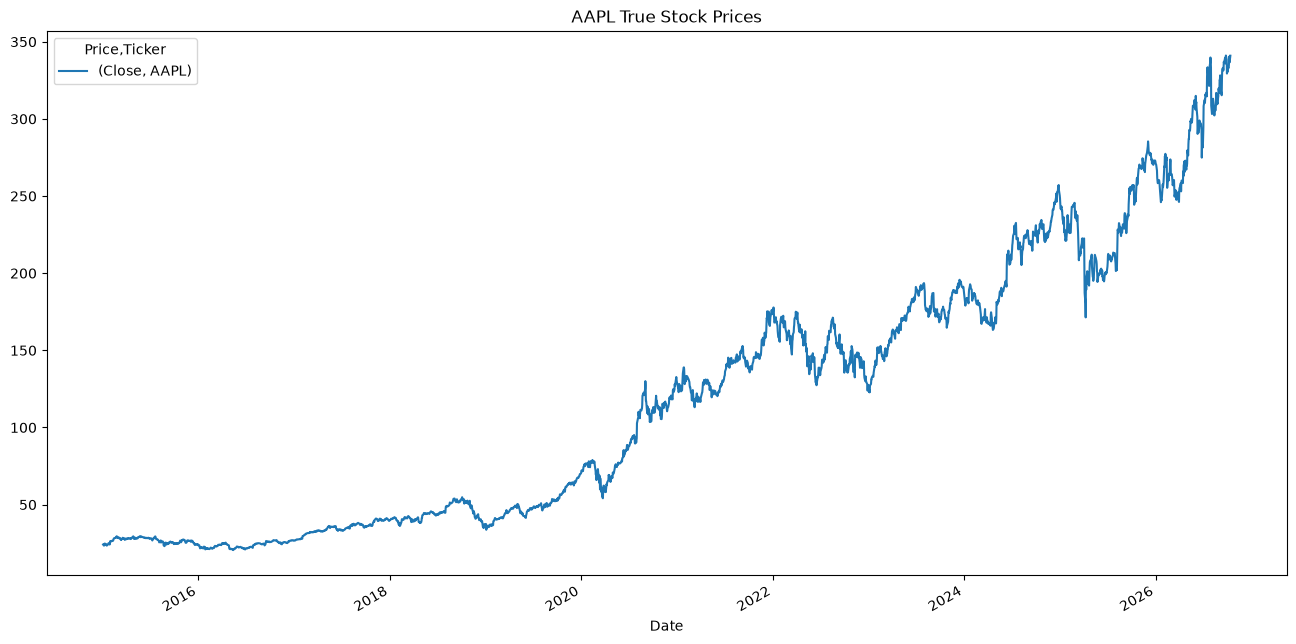

In [3]:
dataset.plot(style='-', figsize=(16, 8), title='AAPL True Stock Prices')
plt.show()

### Creating Chronological Train-Test Splits

Because this is time-series data, I will split the dataset chronologically rather than randomly.  The training set will contain data from 2015 through 2023, while the test set will contain all data after 2023.

To create this split, I will use a custom `train_test_split()` function with the parameters `dataset`, `tstart`, and `tend`.  The function selects observations whose indexed year falls between `tstart` and `tend` for the training set, while observations after `tend` are assigned to the test set.

I will set `tstart=2015` and `tend=2023` to create the desired training and test periods.

In [4]:
def train_test_split(dataset, tstart, tend):
    training_set = dataset[ (dataset.index.year >= tstart) & (dataset.index.year <= tend) ]
    test_set = dataset[ dataset.index.year > tend ]

    return training_set, test_set

In [5]:
training_set, test_set = train_test_split(
    dataset=dataset,
    tstart=2015,
    tend=2023
)

### Data Scaling

Since neural networks can be sensitive to the scale of the input data, I will use `MinMaxScaler()` from scikit-learn to scale the closing prices to a range between 0 and 1.

The scaler will be fit and transformed using only the training data.  The test data will then be transformed using the same scaler without fitting it again.  This prevents information from the test set from being used during the training process and helps avoid data leakage.

In [6]:
# scale with MinMaxScaler()
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(training_set)
test_scaled = scaler.transform(test_set)    # test set only gets transform() to avoid leaking information from the test set

### Transform the Time-Series Dataset into a Prediction Dataset

Now that the data has been split and scaled, I will transform the time-series data into sequences that can be used by the LSTM.

I will create a function called `create_dataset()` with the parameters `dataset` and `lookback`.  The function uses the specified number of previous observations as the input features and the following observation as the target.

For this project, I will use a lookback period of 60 trading days.  This means that each input sequence contains the previous 60 days of closing prices, and the target is the closing price for the following day.

I will then use `create_dataset()` to create the training and test features (`X_train` and `X_test`) and targets (`y_train` and `y_test`).  I will print the shape of each dataset to verify that the sequences were created correctly.

In [7]:
def create_dataset(dataset, lookback):
    """Transform a time series into a prediction dataset.

    Args:
        dataset: A 2D numpy array (time_steps, features)
        lookback: Number of past time steps to use as input
    """
    X, y = [], []

    for i in range(len(dataset) - lookback):
        feature = dataset[ i : i+lookback ]
        target = dataset[ i+lookback ]
        
        X.append(feature)
        y.append(target)
    
    return (
        torch.tensor(np.array(X), dtype=torch.float32),
        torch.tensor(np.array(y), dtype=torch.float32)
    )

In [8]:
# use 60 previous days to predict the next day
lookback = 60

X_train, y_train = create_dataset(train_scaled, lookback=lookback)
X_test, y_test = create_dataset(test_scaled, lookback=lookback)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

torch.Size([2204, 60, 1]) torch.Size([2204, 1])
torch.Size([637, 60, 1]) torch.Size([637, 1])


## Data Loading

Now that the features and targets have been created, I will create `DataLoader` objects for the training and test datasets.

I will use `TensorDataset()` to combine the features and targets into dataset objects and then use `DataLoader()` to divide the data into batches.  The batch size will be set to 64.

For the training data, I will use `shuffle=True` so that the order of the training sequences is randomized between epochs.  The test data will use `shuffle=False` because the order of the test observations should be preserved when evaluating the model.

In [9]:
# create data loaders
train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    shuffle=True,
    batch_size=64
)

test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    shuffle=False,
    batch_size=64
)

In [10]:
X_batch, y_batch = next(iter(train_loader))

print(X_batch.shape)
print(y_batch.shape)

torch.Size([64, 60, 1])
torch.Size([64, 1])


## Define LSTM Model

The LSTM model was constructed with an `input_size` of 1 because the model uses only the daily closing price as its input feature.  The LSTM contains 64 features in its hidden state (`hidden_size = 64`) and consists of two stacked LSTM layers (`num_layers = 2`) to allow the model to learn patterns across the time series.  The model uses a learnable bias (`bias = True`), which allows the LSTM to learn a bias term along with its other parameters and gives it a little more flexibility when learning patterns in the stock price data.

The `batch_first = True` parameter specifies that input tensors are organized with the batch size as the first dimension, followed by the sequence length and number of features.  Finally, a dropout rate of 0.2 (`dropout = 0.2`) was applied between the LSTM layers as a regularization technique to reduce overfitting. This means that 20% of the outputs between the LSTM layers are randomly dropped during training.

## Forward Pass

The `forward()` method defines how the input data passes through the model.  First, the input tensor is passed through the two-layer LSTM.  The LSTM then returns an output for each time step, along with the final hidden and cell states.  Since the goal is to predict the closing price for the next day, only the output from the final step is selected using `x = x[:, -1, :]`.  This output is then passed through the linear layer, which produces the predicted closing price.  Finally, the prediction is then returned as the model's output.

In [11]:
class LSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=64,
            num_layers=2,
            bias=True,
            batch_first=True,
            dropout=0.2

        )

        self.linear = nn.Linear(64, 1)

    def forward(self, x):
        x, _ = self.lstm(x)
        x = x[:, -1, :]
        x = self.linear(x)
        return x

## Training and Verifying LSTM Network

Before training the model, I will define the loss function and optimizer.  I will use Mean Squared Error (`MSELoss`) as the loss function because this is a regression problem where the goal is to predict a continuous closing price.  The Adam optimizer will be used with a learning rate of `5e-4` to update the model's parameters during training.

The model will be trained for a maximum of 2,000 epochs using a batch size of 64.  During each epoch, the training data will be divided into batches and passed through the model.  The predicted values will be compared with the actual target values using MSE loss, and the resulting loss will be used to update the model's parameters through backpropagation.

Training loss will be tracked for each epoch so that the model's learning process can be examined.  I will also calculate the training and test RMSE every 100 epochs to monitor model performance and identify potential overfitting.

Early stopping will be used to stop training when the test RMSE no longer improves.  The model state with the lowest test RMSE observed during the training process will be retained for the final evaluation.

In [12]:
model = LSTM()

optimizer = optim.Adam(
    model.parameters(),
    lr=5e-4
)

loss_fn = nn.MSELoss()

## Model Evaluation

The final model will be evaluated using Root Mean Squared Error (RMSE), which is the evaluation metric specified for this project.  RMSE measures the typical difference between the predicted and actual values, with larger errors having a greater effect on the final value.

The model's performance will be evaluated using the test data, which contains observations from 2024 onward that were not included in the training data.  A lower RMSE indicates that the model's predictions are closer to the actual closing price.

This evaluation will run for a maximum of 2000 epochs while tracking training and test losses and RMSE at each epoch.  The model with the lowest test RMSE will be saved so that its weights can be restored after training.  Early stopping will be implemented with a patience of 100 epochs, allowing training to continue for up to 100 additional epochs without improvement before stopping.

In [13]:
n_epochs = 2000

# track losses
train_losses = []

best_test_rmse = float('inf')
best_model_state = None
patience = 100
epochs_without_improvement = 0

for epoch in range(n_epochs):
    model.train()

    epoch_loss = 0

    for X_batch, y_batch in train_loader:
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    train_losses.append(epoch_loss / len(train_loader))

    # Validation
    if epoch % 100 != 0:
        continue

    model.eval()

    with torch.no_grad():
        y_pred = model(X_train)
        train_rmse = torch.sqrt(loss_fn(y_pred, y_train))
        y_pred = model(X_test)
        test_rmse = torch.sqrt(loss_fn(y_pred, y_test))

    print(f"Epoch {epoch}: train RMSE {train_rmse:.4f}, test RMSE {test_rmse:.4f}")

    # implement early stopping
    if test_rmse < best_test_rmse:
        best_test_rmse = test_rmse
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 100

    if epochs_without_improvement >= patience:
        print('Early Stopping')
        break

model.load_state_dict(best_model_state)

print(f'Best Test RMSE: {best_test_rmse:.4f}')

Epoch 0: train RMSE 0.2487, test RMSE 0.6417
Epoch 100: train RMSE 0.0158, test RMSE 0.0511
Epoch 200: train RMSE 0.0127, test RMSE 0.0269
Epoch 300: train RMSE 0.0122, test RMSE 0.0315
Early Stopping
Best Test RMSE: 0.0269


## Visualizing the Predictions and Losses

After training is complete, I will use the final selected model to generate predictions for both the training and test datasets.  The model will be placed in evaluation mode, and gradient tracking will be disabled during prediction.

The predictions and actual test values will be transformed back to their original dollar scale using the inverse transformation from the `MinMaxScaler()`.  I will then calculate the test root mean squared error (RMSE) in dollars to measure the magnitude of the model's prediction errors in the original units.

Next, the actual closing prices and model predictions will be plotted together to compare the model's performance across the training and test periods.  Finally, the training and test losses will be plotted across epochs to examine the model's learning progress and identify potential signs of overfitting.

Test RMSE Dollars:  4.7202


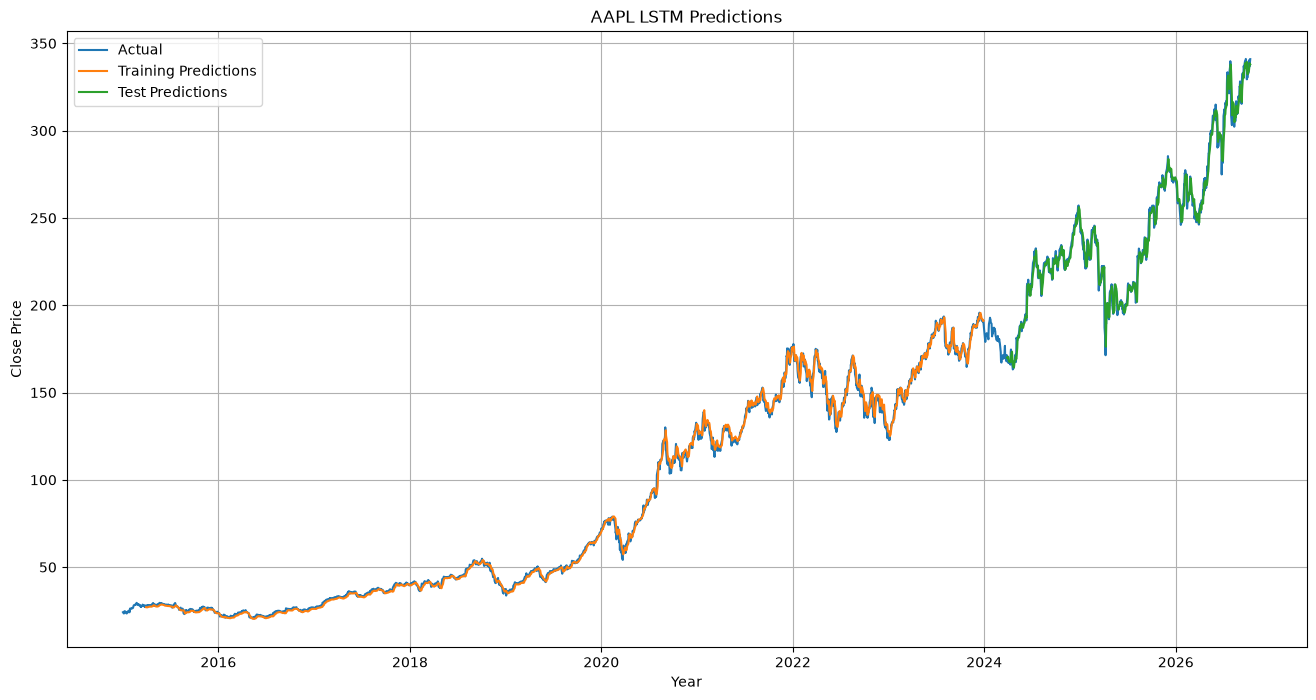

In [14]:
# make predictions
model.eval()

with torch.no_grad():
    train_pred = model(X_train).numpy()
    test_pred = model(X_test).numpy()

# convert preds back to actual dollar values
train_pred = scaler.inverse_transform(train_pred)
test_pred = scaler.inverse_transform(test_pred)
test_actual = scaler.inverse_transform(y_test.numpy())

# calculate test RMSE in dollars
test_rmse_dollars = np.sqrt(
    np.mean((test_pred - test_actual) ** 2)
)

print(f'Test RMSE Dollars: {test_rmse_dollars: .4f}')

# create arrays for plotting
train_plot = np.full(len(dataset), np.nan)
test_plot = np.full(len(dataset), np.nan)

# put training preds in their correct positions
train_plot[ lookback:len(training_set) ] = train_pred.flatten()

# put test preds in their correct positions
test_start = len(training_set)
test_plot[ test_start + lookback: ] = test_pred.flatten()

# plot
plt.figure(figsize=(16, 8))

plt.plot(dataset.index, dataset, label='Actual')
plt.plot(dataset.index, train_plot, label='Training Predictions')
plt.plot(dataset.index, test_plot, label='Test Predictions')

plt.title('AAPL LSTM Predictions')
plt.xlabel('Year')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()

The training loss was plotted across epochs to observe how the model's performance changed during training.  The y-axis uses a logarithmic scale to make changes in loss easier to visualize, particularly when the loss decreases sharply during the initial epochs and more gradually afterward.

The plot helps assess whether the model is learning from the training data and whether the loss begins to plateau as training progresses.  However, training loss alone does not indicate how well the model generalizes to unseen data, so it should be considered alongside test RMSE when evaluating model performance.

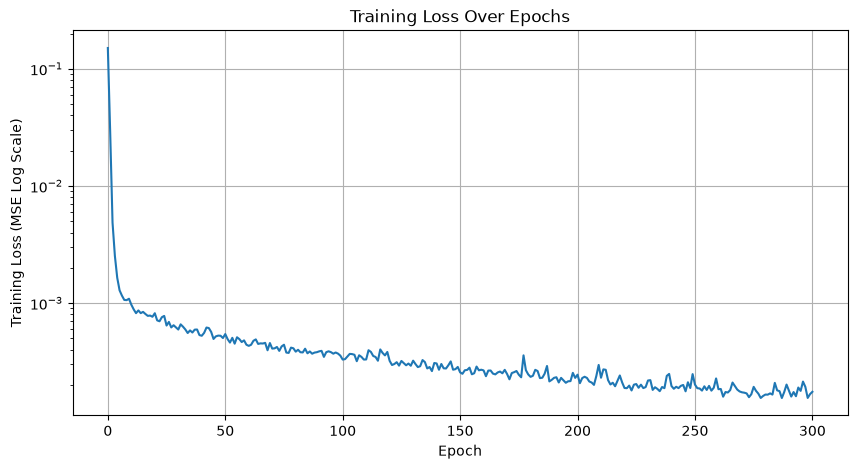

In [15]:
plt.figure(figsize=(10,5))

plt.plot(train_losses)
plt.yscale('log')

plt.xlabel('Epoch')
plt.ylabel('Training Loss (MSE Log Scale)')
plt.title('Training Loss Over Epochs')
plt.grid(True)
plt.show()

## Results and Analysis

The final model achieved a scaled test RMSE of 0.0269 and an inverse-transformed test RMSE of $4.7202 in U.S. dollars.  The scaled RMSE measures prediction error in the normalized target's units, while the inverse-transformed RMSE expresses the error in the original AAPL closing-price scale, making it easier to interpret in practical terms.

The prediction plot shows how closely the model's predictions followed the actual AAPL closing prices during the test period.

The training and test RMSE values can also be compared to evaluate how well the model generalizes to unseen data.  If the training error continues to decrease while the test error begins to increase, this can indicate that the model is overfitting the training data.  Dropout and early stopping help address this issue by providing regularization and retaining the model checkpoint with the best observed test performance.

In [ ]:
torch.save(model.state_dict(), 'aapl-lstm-forecasting.pth')